# 1 · One language for failure

MTBF, availability, mission reliability and readiness for the synthetic navigation system,
physical failures only. See [Lesson 1](../docs/lessons/01-one-language-for-failure.md).

In [1]:
import matplotlib.pyplot as plt

from cyberrel import plotting

plotting.use_style()

In [2]:
from cyberrel.system_model import (
    MISSION_HOURS,
    mission_reliability,
    navigation_system,
    steady_state,
    steady_state_status,
)

system = navigation_system()
print(system.summary())
s = steady_state(system)
print(f"A = {s.availability:.6f}   MTBF = {s.mtbf:,.0f} h   MDT = {s.mdt:.2f} h")
print(f"10 h mission unreliability = {1 - mission_reliability(system, MISSION_HOURS):.3e}")
status = steady_state_status(system)
print(f"FMC {status.fmc_rate:.4f}   PMC {status.pmc_rate:.4f}   MC {status.mc_rate:.6f}")

navigation (2 EGI, 2 bus channels): series(parallel(series(egi_1, power_bus_1), series(egi_2, power_bus_2)), parallel(bus_ch_a, bus_ch_b), mission_computer, parallel(power_bus_1, power_bus_2))
A = 0.999800   MTBF = 19,874 h   MDT = 3.99 h
10 h mission unreliability = 5.047e-04
FMC 0.9982   PMC 0.0016   MC 0.999800


Where system failures come from: failure frequency times Birnbaum importance.

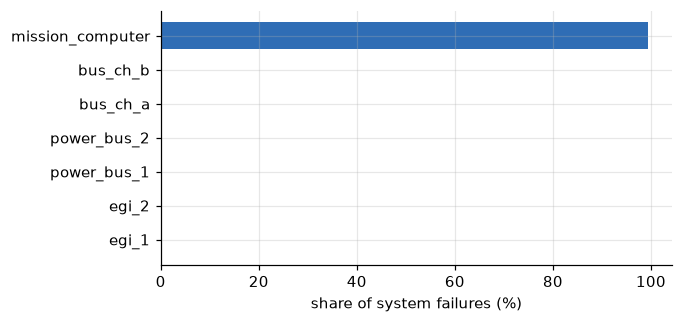

In [3]:
from cyberrel.system_model import availabilities, birnbaum_importance
from cyberrel.system_model.closed_form import failure_frequencies

ib = birnbaum_importance(system, availabilities(system))
nu = failure_frequencies(system)
share = {n: nu[n] * ib[n] / s.failure_frequency for n in system.names}
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(list(share), [100 * v for v in share.values()], color=plotting.PHYSICAL_COLOR)
ax.set_xlabel("share of system failures (%)");

The same mission unreliability from CPS-02's failure-logic model (`cpsrbd`).

In [4]:
from cpsrbd.consequence_driven_analysis import navigation_case_study
from cpsrbd.probability_likelihood_propagation import exact_probability, origin_overrides
from cpsrbd.unified_graph_model import Origin

model = navigation_case_study(mission_hours=MISSION_HOURS)
cps02 = exact_probability(model, origin_overrides(model, Origin.PHYSICAL))
here = 1 - mission_reliability(system, MISSION_HOURS)
print(f"CPS-02 {cps02:.15e}\nCPS-01 {here:.15e}\ndifference {abs(cps02 - here):.1e}")

CPS-02 5.047119663569955e-04
CPS-01 5.047119663570410e-04
difference 4.5e-17
